In [2]:
# Checking the data
DATA_DIR = "../test_data"
PLOTS_DIR = "../results/plots"
RESULTS_DIR = "../results"

In [3]:
# Imports
import os, glob, time
import numpy as np
import pandas as pd
import librosa, librosa.display
import pretty_midi
import matplotlib.pyplot as plt

In [4]:
# Finding the wav + midi pairs in the data directory
os.makedirs(PLOTS_DIR, exist_ok=True)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def find_pairs(data_dir):
    midi_by_stem = {}
    for path in glob.glob(os.path.join(data_dir, "**", "*"), recursive=True):
        if os.path.isfile(path) and os.path.splitext(path)[1].lower() in (".mid", ".midi"):
            stem = os.path.normcase(os.path.splitext(path)[0])
            midi_by_stem[stem] = path

    pairs = []
    for wav in sorted(glob.glob(os.path.join(data_dir, "**", "*.wav"), recursive=True)):
        stem = os.path.normcase(os.path.splitext(wav)[0])
        if stem in midi_by_stem:
            pairs.append((wav, midi_by_stem[stem]))
    return pairs

pairs = find_pairs(DATA_DIR)
print(f"Found {len(pairs)} WAV + MIDI pairs")
if not pairs:
    print(f"Warning: no matching files found under {os.path.abspath(DATA_DIR)}. Check DATA_DIR and the file locations.")

SECONDS = 120   # only use the first 2 minutes of each file, so it runs fast
rows = []

Found 10 WAV + MIDI pairs


In [5]:
# Resampling the audio to 22.05 kHz and checking how much energy is lost above 11 kHz
wav_path, midi_path = pairs[0]
t0 = time.time(); y_orig, sr_orig = librosa.load(wav_path, sr=None, duration=SECONDS); t1 = time.time() - t0
t0 = time.time(); y_22, sr_22 = librosa.load(wav_path, sr=22050, duration=SECONDS); t2 = time.time() - t0
print(f"Original: {sr_orig} Hz, {y_orig.nbytes/1e6:.1f} MB, {t1:.2f} s")
print(f"22.05k:   {sr_22} Hz, {y_22.nbytes/1e6:.1f} MB, {t2:.2f} s")

S = np.abs(librosa.stft(y_orig)) ** 2
freqs = librosa.fft_frequencies(sr=sr_orig)
high = S[freqs > 11025].sum() / S.sum() * 100
print(f"Energy above 11 kHz: {high:.3f}%")

rows.append({"Experiment": "Resampling", "Options": f"{sr_orig} vs 22050 Hz",
             "What I saw": f"Half the size; {high:.3f}% of energy lost",
             "Choice": "22050 Hz", "Why": "Piano energy is well below 11 kHz; cheaper to train"})

Original: 44100 Hz, 21.2 MB, 4.06 s
22.05k:   22050 Hz, 10.6 MB, 0.16 s
Energy above 11 kHz: 0.000%


In [6]:
# Checking the correlation between left and right channel loudness  
y_st, _ = librosa.load(wav_path, sr=22050, mono=False, duration=SECONDS)
corr = 1.0 if y_st.ndim == 1 else np.corrcoef(librosa.feature.rms(y=y_st[0])[0],
                                               librosa.feature.rms(y=y_st[1])[0])[0, 1]
print(f"Left vs right loudness: r = {corr:.3f}")
rows.append({"Experiment": "Mono", "Options": "stereo vs mono", "What I saw": f"L/R loudness r = {corr:.3f}",
             "Choice": "mono", "Why": "Both channels carry the same dynamics"})

Left vs right loudness: r = 0.981


In [7]:
# Checking which amplitude normalisation keeps loudness linked to MIDI velocity
SEG = 5   # segment length in seconds
# cut the audio into 5 s segments, each paired with the mean velocity of its notes
def get_segments(wav_path, midi_path, sr=22050):
    y, _ = librosa.load(wav_path, sr=sr, duration=SECONDS)
    notes = [n for i in pretty_midi.PrettyMIDI(midi_path).instruments for n in i.notes]
    st = np.array([n.start for n in notes]); vl = np.array([n.velocity for n in notes])
    out = []
    for k in range(len(y) // (SEG * sr)):
        m = (st >= k*SEG) & (st < (k+1)*SEG)
        if m.sum():
            out.append({"seg": y[k*SEG*sr:(k+1)*SEG*sr], "file_peak": np.abs(y).max(), "velocity": vl[m].mean()})
    return out

segs = [s for w, m in pairs for s in get_segments(w, m)]
vel = np.array([s["velocity"] for s in segs])
def loud_db(x): return 20 * np.log10(np.sqrt(np.mean(x**2)) + 1e-9)

versions = {
    "None":              [loud_db(s["seg"]) for s in segs],
    "Peak, per file":    [loud_db(s["seg"] / s["file_peak"]) for s in segs],
    "Peak, per segment": [loud_db(s["seg"] / (np.abs(s["seg"]).max() + 1e-9)) for s in segs],
    "RMS, per segment":  [loud_db(s["seg"] / (np.sqrt(np.mean(s["seg"]**2)) + 1e-9)) for s in segs],
}
corrs = {}
for name, loud in versions.items():
    loud = np.array(loud)
    corrs[name] = 0.0 if loud.std() < 0.01 else np.corrcoef(loud, vel)[0, 1]
    print(f"{name:18s} r = {corrs[name]:.2f}")

rows.append({"Experiment": "Amplitude normalisation", "Options": "none / per file / per segment",
             "What I saw": ", ".join(f"{k}: {v:.2f}" for k, v in corrs.items()),
             "Choice": "none", "Why": "Per-segment normalisation removes the loudness we must predict"})

None               r = 0.72
Peak, per file     r = 0.75
Peak, per segment  r = 0.06
RMS, per segment   r = 0.00


In [8]:
# Checking the segment length
total = sum(min(SECONDS, librosa.get_duration(path=w)) for w, _ in pairs)
for L in (5, 10):
    print(f"{L} s: {int(total//L)} examples, {int(L*22050/512)+1} frames each")
rows.append({"Experiment": "Segment length", "Options": "5 vs 10 s",
             "What I saw": f"5 s = {int(total//5)} examples, 10 s = {int(total//10)}",
             "Choice": "5 s", "Why": "Twice the examples; still long enough for a crescendo"})

5 s: 231 examples, 216 frames each
10 s: 115 examples, 431 frames each


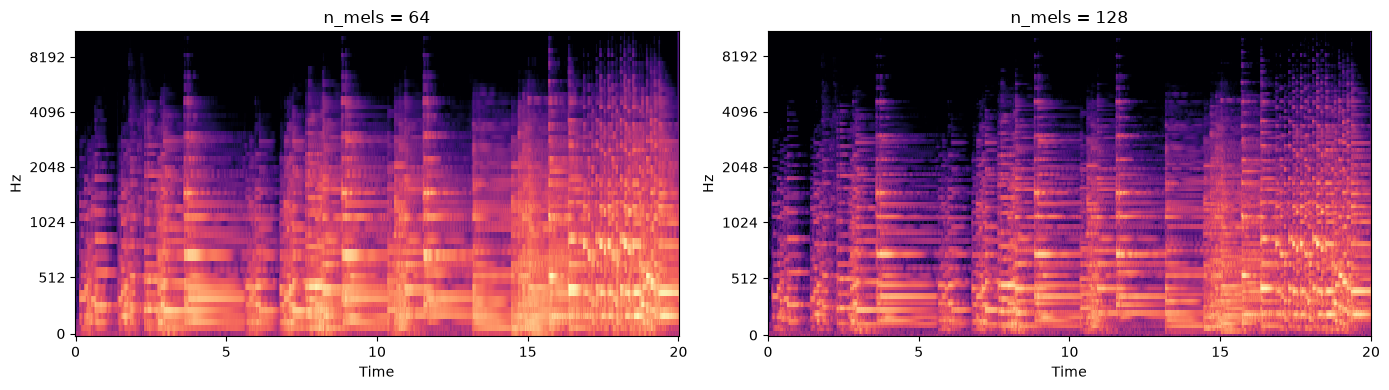

In [9]:
# Compare mel resolutions while reusing the same STFT for both
SR = 22050
HOP_LENGTH = 512
N_FFT = 2048

y5, _ = librosa.load(wav_path, sr=SR, duration=20, mono=True)
power_spec = np.abs(librosa.stft(y5, n_fft=N_FFT, hop_length=HOP_LENGTH)) ** 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, n in zip(axes, (64, 128)):
    mel_basis = librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=n)
    mel_db = librosa.power_to_db(mel_basis @ power_spec, ref=np.max)
    librosa.display.specshow(
        mel_db, sr=SR, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax
    )
    ax.set_title(f"n_mels = {n}")

fig.tight_layout()
fig.savefig(os.path.join(PLOTS_DIR, "02_n_mels.png"), dpi=120)
plt.show()
rows.append({"Experiment": "n_mels", "Options": "64 vs 128", "What I saw": "128 shows notes more clearly",
             "Choice": "128", "Why": "Finer pitch detail; common in music deep learning"})

In [10]:
# Checking different hop lengths
for hop in (256, 512):
    fps = 22050 / hop
    print(f"hop={hop}: {fps:.1f} frames/s, one every {1000/fps:.1f} ms")
rows.append({"Experiment": "hop_length", "Options": "256 vs 512", "What I saw": "512 = 23 ms per frame",
             "Choice": "512", "Why": "Dynamics/tempo change over 100s of ms; 23 ms is enough"})

hop=256: 86.1 frames/s, one every 11.6 ms
hop=512: 43.1 frames/s, one every 23.2 ms


In [11]:
# Checking the dB reference: per-clip max vs a fixed 1.0
def mel_mean(seg, ref):
    return librosa.power_to_db(librosa.feature.melspectrogram(y=seg, sr=22050, n_mels=128, hop_length=512), ref=ref).mean()
r_max   = np.corrcoef([mel_mean(s["seg"], np.max) for s in segs], vel)[0, 1]
r_fixed = np.corrcoef([mel_mean(s["seg"], 1.0)    for s in segs], vel)[0, 1]
print(f"ref=np.max: r = {r_max:.2f}   ref=1.0: r = {r_fixed:.2f}")
rows.append({"Experiment": "dB reference", "Options": "np.max vs 1.0", "What I saw": f"{r_max:.2f} vs {r_fixed:.2f}",
             "Choice": "ref=1.0 + standardise on train only", "Why": "Per-clip ref hides loudness; avoids leakage"})

ref=np.max: r = 0.60   ref=1.0: r = 0.77


In [12]:
# Saving the results to a CSV file
results = pd.DataFrame(rows)
results.to_csv(os.path.join(RESULTS_DIR, "preprocessing_results.csv"), index=False)
results

,Experiment,Options,What I saw,Choice,Why
0,Resampling,44100 vs 22050 Hz,Half the size; 0.000% of energy lost,22050 Hz,Piano energy is well below 11 kHz; cheaper to ...
1,Mono,stereo vs mono,L/R loudness r = 0.981,mono,Both channels carry the same dynamics
2,Amplitude normalisation,none / per file / per segment,"None: 0.72, Peak, per file: 0.75, Peak, per se...",none,Per-segment normalisation removes the loudness...
3,Segment length,5 vs 10 s,"5 s = 231 examples, 10 s = 115",5 s,Twice the examples; still long enough for a cr...
4,n_mels,64 vs 128,128 shows notes more clearly,128,Finer pitch detail; common in music deep learning
5,hop_length,256 vs 512,512 = 23 ms per frame,512,Dynamics/tempo change over 100s of ms; 23 ms i...
6,dB reference,np.max vs 1.0,0.60 vs 0.77,ref=1.0 + standardise on train only,Per-clip ref hides loudness; avoids leakage
